# Exploratory Data Analysis: Bank Term-Deposit Propensity

Dataset: Bank Marketing (UCI, `bank-additional-full.csv`), telemarketing campaigns of a Portuguese bank from May 2008 to November 2010.

Goal: understand the data from a business perspective and confirm the known pitfalls before building the pipeline.

## 1. Load the data

The raw file path comes from `params.yaml`, the same source used by the pipeline. `load_raw_dataset` reads the CSV and renames the original UCI columns to descriptive snake_case names (for example `y` becomes `subscribed`, `default` becomes `has_credit_default`).

In [57]:
import matplotlib.pyplot as plt
import pandas as pd

from bank_propensity_pipeline.config import PROJECT_ROOT, load_params
from bank_propensity_pipeline.data.schema import TARGET_COLUMN, load_raw_dataset

params = load_params()
df = load_raw_dataset(PROJECT_ROOT / params["data"]["raw_path"])
df.shape


(41188, 21)

## 2. Data quality checks

The next cells check, in order:

1. **Column structure:** data types and missing values for each column.
2. **Target distribution:** `subscribed` indicates whether the client subscribed to a term deposit. The class balance defines which metrics make sense.
3. **"unknown" values:** missing information is encoded as the string `"unknown"` in categorical columns. We will keep it as its own category, since missing information can also carry signal.
4. **The `pdays = 999` sentinel:** `pdays` is the number of days since the last contact in a previous campaign. The value `999` means the client was never contacted before, so it is a flag, not a real number of days.

In [58]:
df.head()


,age,job,marital_status,education,has_credit_default,has_housing_loan,has_personal_loan,contact_channel,last_contact_month,last_contact_weekday,...,contacts_this_campaign,days_since_previous_contact,previous_contacts,previous_outcome,employment_variation_rate,consumer_price_index,consumer_confidence_index,euribor_3m,employees_thousands,subscribed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [59]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          41188 non-null  int64  
 1   job                          41188 non-null  str    
 2   marital_status               41188 non-null  str    
 3   education                    41188 non-null  str    
 4   has_credit_default           41188 non-null  str    
 5   has_housing_loan             41188 non-null  str    
 6   has_personal_loan            41188 non-null  str    
 7   contact_channel              41188 non-null  str    
 8   last_contact_month           41188 non-null  str    
 9   last_contact_weekday         41188 non-null  str    
 10  last_call_duration_sec       41188 non-null  int64  
 11  contacts_this_campaign       41188 non-null  int64  
 12  days_since_previous_contact  41188 non-null  int64  
 13  previous_contacts          

In [60]:
df[TARGET_COLUMN].value_counts(normalize=True).round(4)


subscribed
no     0.8873
yes    0.1127
Name: proportion, dtype: float64

In [61]:
(df == "unknown").sum().loc[lambda s: s > 0].sort_values(ascending=False)


has_credit_default    8597
education             1731
has_housing_loan       990
has_personal_loan      990
job                    330
marital_status          80
dtype: int64

In [62]:
(df["days_since_previous_contact"] == 999).mean().round(4)


np.float64(0.9632)

## 3. Conversion drivers

Conversion rate is the share of contacted clients who subscribed (`subscribed = yes`). The next cells compare it across:

1. **Previous campaign outcome (`previous_outcome`):** do clients who subscribed before subscribe again?
2. **Credit default status (`has_credit_default`):** does an `unknown` answer behave differently from `no`?
3. **Contact channel (`contact_channel`) and job (`job`):** which channels and profiles convert better?
4. **Number of contacts in the campaign (`contacts_this_campaign`):** does insisting help or hurt?
5. **Interest rate context (`euribor_3m`):** how does the macroeconomic scenario affect conversion?

In [63]:
df["subscribed_flag"] = (df[TARGET_COLUMN] == "yes").astype(int)


def conversion_by(column: str | pd.Series) -> pd.DataFrame:
    """Return client count and conversion rate for each category of a column."""
    return (
        df.groupby(column, observed=True)["subscribed_flag"]
        .agg(clients="count", conversion_rate="mean")
        .sort_values("conversion_rate", ascending=False)
        .round(4)
    )


In [64]:
conversion_by("previous_outcome")


,clients,conversion_rate
previous_outcome,,
success,1373,0.6511
failure,4252,0.1423
nonexistent,35563,0.0883


In [65]:
conversion_by("has_credit_default")


,clients,conversion_rate
has_credit_default,,
no,32588,0.1288
unknown,8597,0.0515
yes,3,0.0000


In [66]:
conversion_by("contact_channel")


,clients,conversion_rate
contact_channel,,
cellular,26144,0.1474
telephone,15044,0.0523


In [67]:
conversion_by("job")


,clients,conversion_rate
job,,
student,875,0.3143
retired,1720,0.2523
unemployed,1014,0.1420
admin.,10422,0.1297
management,2924,0.1122
unknown,330,0.1121
technician,6743,0.1083
self-employed,1421,0.1049
housemaid,1060,0.1000


In [68]:
campaign_bins = pd.cut(df["contacts_this_campaign"], bins=[0, 1, 2, 3, 5, 10, 60])
conversion_by(campaign_bins.rename("contacts_this_campaign_range")).sort_index()


,clients,conversion_rate
contacts_this_campaign_range,,
"(0, 1]",17642,0.1304
"(1, 2]",10570,0.1146
"(2, 3]",5341,0.1075
"(3, 5]",4250,0.0868
"(5, 10]",2516,0.0632
"(10, 60]",869,0.0311


In [69]:
df["euribor_quintile"] = pd.qcut(df["euribor_3m"], q=5, duplicates="drop")
conversion_by("euribor_quintile").sort_index()


,clients,conversion_rate
euribor_quintile,,
"(0.633, 1.299]",8636,0.2965
"(1.299, 4.191]",8430,0.1078
"(4.191, 4.864]",8446,0.0362
"(4.864, 4.962]",8498,0.0552
"(4.962, 5.045]",7178,0.0550


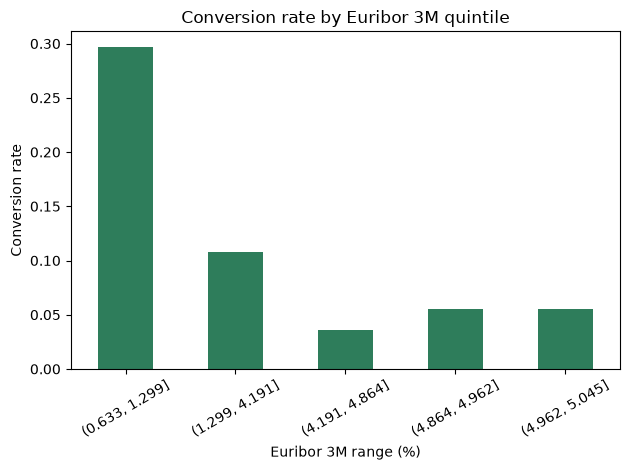

In [70]:
euribor_conversion = conversion_by("euribor_quintile").sort_index()
ax = euribor_conversion["conversion_rate"].plot(kind="bar", color="#2E7D5B")
ax.set(
    title="Conversion rate by Euribor 3M quintile",
    xlabel="Euribor 3M range (%)",
    ylabel="Conversion rate",
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 4. Key findings and pipeline decisions

**Data quality**

- 41,188 contacts, 21 columns and no null values. Missing information is hidden as the string `"unknown"`, mostly in `has_credit_default` (21% of rows).
- `days_since_previous_contact = 999` for 96.3% of clients, meaning they were never contacted before. The raw number is not meaningful, so it will be handled as a "never contacted" flag.
- `last_call_duration_sec` is only known after the call ends, so it is data leakage and will be dropped.

**Target**

- Only 11.3% of clients subscribed. A model that always predicts "no" reaches 88.7% accuracy and finds no subscribers, so accuracy is misleading. We will use a stratified split and PR-AUC as the main metric.

**Conversion drivers**

- **Past success is the strongest signal:** clients who subscribed in a previous campaign convert at 65.1%, against 8.8% for clients never contacted before.
- **"unknown" carries information:** clients with unknown default status convert at 5.2%, less than half of those who answered "no" (12.9%). It will be kept as its own category.
- **Channel and profile matter:** cellular converts at 14.7% against 5.2% for landline. Students (31.4%) and retired clients (25.2%) convert the most, blue-collar workers (6.9%) the least.
- **Insisting hurts:** conversion falls from 13.0% at the first contact to 3.1% after more than 10 contacts. A contact cap per client is a direct business recommendation.
- **Macroeconomic context dominates:** conversion is 29.7% when Euribor 3M is below 1.3%, against 3.6% to 5.5% when it is above 4.2%. Low rates match the post-2008 crisis period, so Euribor likely acts as a proxy for time and market regime rather than a direct cause. This makes the model sensitive to economic drift, a limitation to document in the Model Card.

**Decisions for the pipeline**

| Finding | Decision |
|---|---|
| `last_call_duration_sec` is leakage | Drop it in the preprocess stage |
| `days_since_previous_contact = 999` | Handle as a "never contacted" flag |
| `"unknown"` values carry signal | Keep as a category in one-hot encoding |
| 11.3% positive class | Stratified split and PR-AUC as the main metric |
| Macro features encode the time period | Document drift risk in the Model Card |